# Clase 7 · Parte 2: ¿le sirve el MCP a Claude?

[evaluar.py](evaluar.py) le hace cada pregunta a Claude Code en modo no interactivo (`claude -p`, con Haiku) de dos
formas: **solo con su memoria** y **con el MCP del BCRP**. Claude debe responder un JSON con el valor y la fuente;
luego se compara con la cifra oficial dentro de una tolerancia de redondeo.

In [ ]:
# Si el kernel elegido no tiene las librerías de esta tarea, se instalan en él (solo la primera vez).
import importlib
import importlib.util
import sys

faltan = [m for m in ("fastmcp", "httpx", "pandas", "matplotlib", "pytest") if importlib.util.find_spec(m) is None]
if faltan:
    print("Instalando", faltan, "en", sys.executable)
    !uv pip install -q --python "{sys.executable}" "fastmcp>=4,<5" httpx pandas matplotlib pytest
    importlib.invalidate_caches()
print("Kernel listo:", sys.executable)

In [1]:
import subprocess

import pandas as pd
from IPython.display import Image

pd.set_option("display.max_colwidth", 140)
preguntas = pd.read_csv("preguntas.csv")
preguntas

,id,pregunta,verdad,tolerancia,serie,periodo
0,ipc_set26,"¿Cuál fue la inflación interanual (variación del IPC en 12 meses) de Lima Metropolitana en setiembre de 2026, en %?",4.5487,0.050,PN01273PM,2026-09
1,ipc_dic25,"¿Cuál fue la inflación interanual (variación del IPC en 12 meses) de Lima Metropolitana en diciembre de 2025, en %?",1.5088,0.050,PN01273PM,2025-12
2,ipc_mar25,"¿Cuál fue la variación mensual del IPC de Lima Metropolitana en marzo de 2025, en %?",0.8102,0.020,PN01271PM,2025-03
3,referencia_set26,"¿Cuál era la tasa de referencia de la política monetaria del BCRP en setiembre de 2026, en %?",4.2500,0.010,PD04722MM,2026-09
4,tc_15oct26,"¿Cuál fue el tipo de cambio interbancario venta del 15 de octubre de 2026 según el BCRP, en soles por dólar?",3.4282,0.002,PD04638PD,2026-10-15
5,rin_ago26,"¿A cuánto ascendían las reservas internacionales netas del BCRP a fines de agosto de 2026, en millones de US$?",96517.9000,100.000,PN00027MM,2026-08
6,cobre_ago26,"¿Cuál fue el precio promedio del cobre en agosto de 2026 según el BCRP, en centavos de US$ por libra?",689.7000,3.500,PN38784BM,2026-08
7,pbi_2025,"¿Cuánto creció el PBI real del Perú en 2025 según el BCRP, en %?",3.4306,0.050,PM04923AA,2025
8,export_ago26,"¿Cuánto sumaron las exportaciones FOB del Perú en agosto de 2026 según el BCRP, en millones de US$?",10815.4000,20.000,PN38714BM,2026-08
9,desempleo_set26,"¿Cuál fue la tasa de desempleo de Lima Metropolitana (promedio móvil de tres meses) en setiembre de 2026 según el BCRP, en %?",4.3717,0.050,PN38063GM,2026-09


Las dos últimas preguntas son mías. Su verdad la saqué de la web del BCRP, no de mi MCP:
[exportaciones FOB](https://estadisticas.bcrp.gob.pe/estadisticas/series/mensuales/resultados/PN38714BM/html/2026-1/2026-9/)
(10,815 millones de US$ en agosto de 2026) y
[desempleo de Lima](https://estadisticas.bcrp.gob.pe/estadisticas/series/mensuales/resultados/PN38063GM/html/2026-1/2026-9/)
(4.4 % en setiembre de 2026, 4.37 con más decimales en la API).

## 1. Correr la evaluación

Las corridas ya están guardadas en `resultados.csv` (base) y `resultados_sin_null.csv` (experimento). Para
repetirlas (unos 3 minutos y 30 llamadas a Claude con tu cuenta), cambia `CORRER` a `True`.

In [2]:
CORRER = False
if CORRER:
    for args in (["evaluar.py"], ["evaluar.py", "--modos", "memoria", "--sin-null", "--salida", "resultados_sin_null.csv"]):
        print(subprocess.run(["uv", "run", *args], capture_output=True, text=True, encoding="utf-8").stdout)

## 2. Resultados por modo

In [3]:
res = pd.concat([pd.read_csv("resultados.csv"), pd.read_csv("resultados_sin_null.csv")], ignore_index=True)
por_modo = res.groupby("modo").resultado.value_counts().unstack(fill_value=0)
por_modo["segundos promedio"] = res.groupby("modo").segundos.mean().round(1)
por_modo.loc[["memoria", "mcp", "memoria sin null"]]

resultado,no sabe,acierta,se equivoca,segundos promedio
modo,,,,
memoria,10,0,0,10.6
mcp,0,10,0,23.5
memoria sin null,9,0,1,6.8


resultado         acierta  no sabe  se equivoca
modo                                           
memoria                 0       10            0
memoria sin null        0        9            1
mcp                    10        0            0


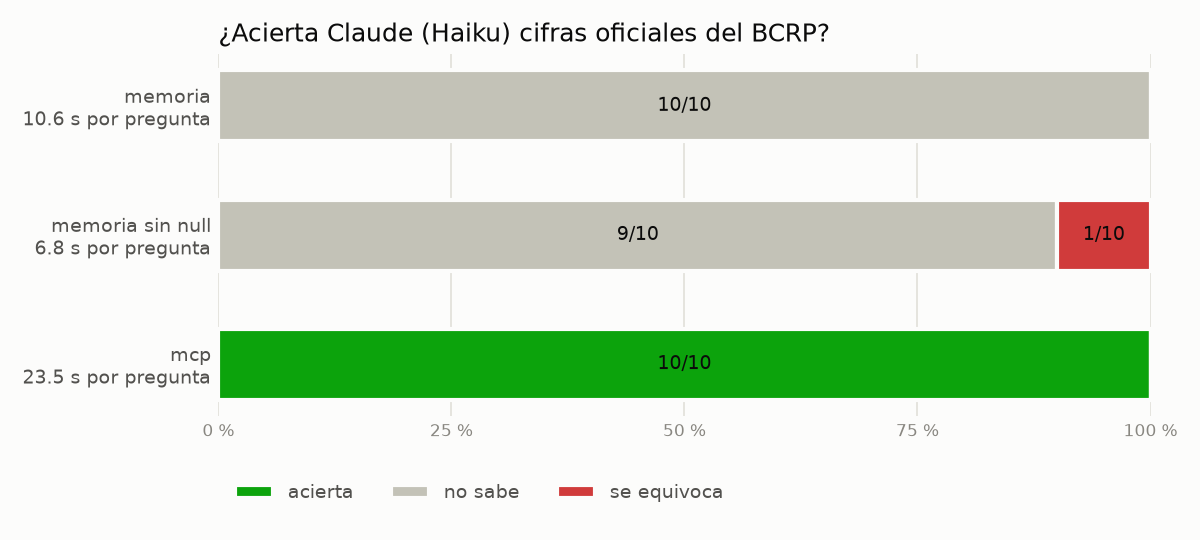

In [4]:
%run graficar.py resultados.csv resultados_sin_null.csv
Image("grafico.png")

## 3. Pregunta por pregunta

In [5]:
valores = res.pivot(index="id", columns="modo", values="valor")
valores.insert(0, "verdad", preguntas.set_index("id").verdad)
valores[["verdad", "mcp", "memoria", "memoria sin null"]]

modo,verdad,mcp,memoria,memoria sin null
id,,,,
cobre_ago26,689.7000,689.698760,NaN,NaN
desempleo_set26,4.3717,4.370000,NaN,NaN
export_ago26,10815.4000,10815.400000,NaN,NaN
ipc_dic25,1.5088,1.510000,NaN,NaN
ipc_mar25,0.8102,0.810000,NaN,0.19
ipc_set26,4.5487,4.550000,NaN,NaN
pbi_2025,3.4306,3.400000,NaN,NaN
referencia_set26,4.2500,4.250000,NaN,NaN
rin_ago26,96517.9000,96517.905835,NaN,NaN


**Con el MCP (10/10)** cada respuesta cita el código de la serie, el periodo y la URL de la API del BCRP. Claude usó
entre 4 y 6 turnos: primero `buscar_series` para encontrar el código y luego `resumen` o `serie`.

In [6]:
res.loc[res.modo == "mcp", ["id", "turnos", "segundos", "fuente"]]

,id,turnos,segundos,fuente
1,ipc_set26,5,45.9,"BCRP, serie PN01273PM ""Índice de precios Lima Metropolitana (var% 12 meses) - IPC"", periodo 2026-09 (valor 4,5487 redondeado a dos decim..."
3,ipc_dic25,5,42.7,"BCRP, serie PN01273PM «Índice de precios Lima Metropolitana (var% 12 meses) - IPC», periodo 2025-12. https://estadisticas.bcrp.gob.pe/es..."
5,ipc_mar25,6,19.7,"BCRP, serie PN01271PM (Índice de precios Lima Metropolitana, var% mensual - IPC), periodo 2025-03. https://estadisticas.bcrp.gob.pe/esta..."
7,referencia_set26,4,13.3,"BCRP, serie PD04722MM (Tasas de interés del Banco Central de Reserva - Tasa de Referencia de la Política Monetaria), periodo 2026-09. AP..."
9,tc_15oct26,4,17.4,"BCRP, serie PD04638PD (Tipo de cambio - TC Interbancario (S/ por US$) - Venta), dato diario del 2026-10-15. API: https://estadisticas.bc..."
11,rin_ago26,4,18.3,"BCRP, serie PN00027MM «Cuentas monetarias del Banco Central de Reserva del Perú - Reservas Internacionales Netas (millones US$)», period..."
13,cobre_ago26,4,16.3,"BCRP, serie PN38784BM (Exportaciones de productos tradicionales – Mineros – Cobre – Precio, ¢US$ por libras), periodo 2026-08. https://e..."
15,pbi_2025,5,23.0,"BCRP, serie PM04923AA (Producto bruto interno por tipo de gasto, variaciones porcentuales reales - PBI), año 2025. Valor original 3,4305..."
17,export_ago26,4,19.1,"BCRP, serie PN38714BM («Balanza comercial - valores FOB (millones US$) - Exportaciones»), periodo 2026-08. https://estadisticas.bcrp.gob..."
19,desempleo_set26,4,19.6,"BCRP, serie PN38063GM (Empleo Mensual en Lima Metropolitana - Promedio móvil tres meses - Tasa de Desempleo (%)), periodo 2026-09. https..."


**Solo con memoria (0/10)** Haiku no tiene cifras de 2026 y, como la instrucción se lo permitía, respondió `null`
las 10 veces:

In [7]:
res.loc[res.modo == "memoria", ["id", "fuente"]].head(3)

,id,fuente
0,ipc_set26,"No tengo acceso a internet ni a datos del INEI en esta sesión, y mi conocimiento llega solo hasta junio de 2026, así que no conozco la c..."
2,ipc_dic25,"No puedo verificar esta cifra. No tengo acceso a internet ni a las publicaciones del INEI en esta sesión, y no conozco con certeza el da..."
4,ipc_mar25,"No tengo acceso a internet ni a una fuente de datos oficial en esta sesión, así que no puedo verificar la cifra. La cifra debe consultar..."


## 4. Experimento extra: sin salida fácil

`--sin-null` quita de la instrucción la frase «Si no puedes saberlo con certeza, pon valor null: no estimes.».
Haiku siguió diciendo que no sabía en 9 de 10, pero en una **inventó una cifra** y la presentó como dato del INEI:

In [8]:
res.loc[res.resultado == "se equivoca", ["id", "modo", "verdad", "valor", "fuente"]]

,id,modo,verdad,valor,fuente
22,ipc_mar25,memoria sin null,0.8102,0.19,"Cifra de memoria, no verificada en vivo (no tengo acceso a internet aquí). Corresponde a la variación mensual del IPC de Lima Metropolit..."


Respondió 0.19 % para la variación mensual del IPC de Lima en marzo de 2025; la oficial es 0.81 %. Es el riesgo de
fondo: un número con apariencia de dato oficial y sin forma de rastrearlo. Con el MCP la misma pregunta devolvió
0.81 % y la URL de la serie PN01271PM.

## 5. Dos cifras comprobadas a mano en la web del BCRP

| Cifra | MCP | Web del BCRP | Tabla |
|---|---|---|---|
| Inflación Lima 12 meses, set-2026 (PN01273PM) | 4.55 % | 4.55 % | [ver tabla](https://estadisticas.bcrp.gob.pe/estadisticas/series/mensuales/resultados/PN01273PM/html/2026-1/2026-9/) |
| Exportaciones FOB, ago-2026 (PN38714BM) | 10,815.40 millones de US$ | 10,815 millones de US$ | [ver tabla](https://estadisticas.bcrp.gob.pe/estadisticas/series/mensuales/resultados/PN38714BM/html/2026-1/2026-9/) |

## 6. Conclusión

Un MCP vale la pena cuando las preguntas se repiten sobre una fuente oficial con API estable y cada cifra tiene que
poder verificarse: aquí pasó de 0 a 10 aciertos, con el código y la URL en cada respuesta. Sin él, el modelo dice que
no sabe o, si se le quita esa salida, puede inventar un número creíble. La búsqueda web basta para preguntas sueltas o
sobre fuentes sin API, aunque depende de encontrar la página correcta. El precio del MCP es construirlo y mantenerlo,
y unos segundos más por pregunta (23.5 s contra 10.6 s de memoria).